# Graph object load

In [1]:
import cdlib
import networkx as nx

# Load objects

In [2]:
# Get graph
output_dir = "/Users/htang/Documents/PhD/Project - CAS/C3_Microbiome/2019-10-24_QIIME_CAS_COAST_meta_5/" + \
    "output/2020-09-25_fastspar_community/"
g = nx.readwrite.read_gml(path=output_dir + "net.graph.all.pos.coast.sick.txt", 
                         label="name")
g

In [3]:
# Get list of taxa
f = open(output_dir + "net.graph.all.pos.node.names.coast.sick.txt", "r")
taxa_list = f.read().splitlines()
taxa_list

['Streptococcus.3575',
 'Moraxella.d253',
 'Dolosigranulum.dd2e',
 'Streptococcus.4060',
 'Streptococcus.b069',
 'Corynebacterium.cb50',
 'Staphylococcus.29eb',
 'Veillonella.fb81',
 'Streptococcus.a3a3',
 'Streptococcus.be1b',
 'Haemophilus.f579',
 'Haemophilus.bc0d',
 'Moraxellaceae.6028',
 'Haemophilus.db79',
 'Veillonella.f2fe',
 'Prevotella.eedc',
 'Gemellaceae.d800',
 'Neisseria.583c',
 'Corynebacterium.b1b8',
 'Rothia.d9a6',
 'Moraxellaceae.a5a0',
 'Rothia.83c4',
 'Moraxellaceae.f2a5',
 'Moraxella.b17f',
 'Veillonella.1230',
 'Granulicatella.c8bb',
 'Rothia.a07c',
 '[Prevotella].a061',
 'Actinomyces.482f',
 'Prevotella.ccff',
 'Actinomyces.15e1',
 'Streptococcus.0524',
 'Granulicatella.86dc',
 'Pasteurellaceae.7682',
 'Prevotella.1cde',
 'Rothia.dacb',
 'Neisseria.30f0',
 'Veillonella.61d8',
 'Corynebacterium.36cb',
 'Rothia.6066',
 'Veillonella.3d26',
 'Leptotrichia.fb2d',
 'Atopobium.e560',
 'Alloiococcus.e018',
 'Porphyromonas.5bb9',
 'Prevotella.6f9b',
 'Neisseriaceae.03f4',

In [4]:
from cdlib import algorithms as cdlibalg
import random
import numpy as np
import matplotlib.pyplot as plt
import bct
from netneurotools import plotting
from netneurotools import cluster

In [5]:
import igraph as ig
import leidenalg as la
import cairo

g2 = ig.Graph.Read_GML(output_dir + "net.graph.all.pos.coast.sick.txt")
g2

In [6]:
# Set number of iterations
iter_range = 100
# Set gamma range
gamma_range = (2, 1, 0.5, 0.25, 0.125)

In [7]:
gamma_range[0]

2

# Community discovery with cdlib

In [8]:
louvain_cdlib_all_gamma=[None]*len(gamma_range)
louvain_cdlib_cons=[None]*len(gamma_range)
for y in range(len(gamma_range)):
    louvain_cdlib_allcoms=[None]*iter_range
    gamma_value = gamma_range[y]
    for x in range(iter_range):
        # x 
        random.seed(x)
        louvain_cdlib_com = cdlibalg.louvain(g, \
                                             resolution=gamma_value, \
                                             randomize=True)
        # louvain_cdlib_com.communities returns taxa names in list of n lists
        # where n is number of communities len(louvain_cdlib_com.communities)
        num_com = len(louvain_cdlib_com.communities)
        # for each taxa in each community
        membership = [None]*len(taxa_list)
        for com in range(num_com):
            for taxa in louvain_cdlib_com.communities[com]:
                # Get index from taxa_list
                index = taxa_list.index(taxa)
                # Make list where index equal to com number
                membership[index] = com
        louvain_cdlib_allcoms[x] = np.array(membership)
    louvain_cdlib_all_gamma[y] = louvain_cdlib_allcoms
    louvain_cdlib_cons[y] = cluster.find_consensus(np.column_stack(louvain_cdlib_allcoms), \
                                                   seed=1)

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 3, 1, 3, 1,
       3, 3, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 3, 2,
       1, 2, 1, 2, 1, 1, 3, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 3, 2, 1,
       2, 3, 2, 1, 1, 2, 2, 2, 3, 2, 2, 2, 2, 1, 2, 2, 1, 1, 2, 2, 2, 2,
       3, 3, 2, 1, 2, 3, 2, 3, 1, 2, 3, 3, 1, 2, 2, 2, 3, 3, 2, 2, 2, 2,
       2, 2, 2, 2, 3, 2, 2, 3, 1, 3, 2, 1, 2, 2, 3, 2, 2, 2, 2, 3, 2, 2,
       2, 2, 2, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 2, 1, 2, 2, 2, 1,
       3, 2, 2, 2, 2, 2, 2, 2, 3, 2, 1, 2, 2, 2, 2, 3, 1, 2, 2, 2, 2, 3,
       2, 2, 2, 3, 1, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 1, 2, 2, 2, 2,

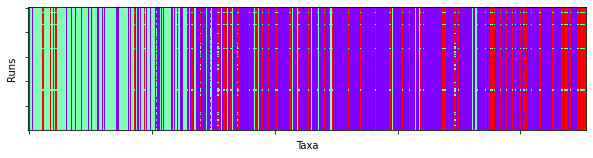

In [9]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_cdlib_all_gamma[0], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_cdlib_cons[0]

array([1, 2, 2, 3, 1, 2, 1, 1, 1, 1, 1, 4, 2, 1, 1, 1, 1, 1, 4, 1, 2, 1,
       2, 4, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 4, 3, 1, 1, 1, 1, 3, 3, 5, 1, 3, 1, 5, 5, 1, 1,
       1, 1, 4, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 1, 1, 3, 1, 3, 1, 1, 4, 3,
       1, 3, 4, 3, 1, 1, 4, 5, 3, 5, 1, 3, 1, 1, 5, 3, 5, 5, 3, 1, 3, 1,
       3, 1, 4, 1, 5, 1, 3, 3, 1, 3, 5, 5, 1, 4, 3, 3, 4, 1, 1, 4, 3, 4,
       3, 4, 3, 4, 1, 5, 3, 5, 4, 3, 3, 3, 3, 1, 3, 3, 5, 4, 3, 3, 3, 3,
       4, 4, 3, 4, 3, 4, 3, 4, 1, 5, 4, 4, 4, 3, 3, 4, 4, 4, 3, 3, 3, 3,
       3, 1, 3, 3, 4, 1, 3, 4, 1, 4, 3, 4, 3, 3, 4, 5, 3, 3, 3, 4, 3, 3,
       3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 3, 1, 3, 3, 3, 5,
       4, 3, 3, 3, 3, 3, 3, 3, 4, 3, 1, 3, 3, 3, 3, 4, 1, 3, 3, 3, 3, 4,
       3, 3, 3, 4, 1, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3,
       3, 3, 3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 1, 3, 3, 3, 3,

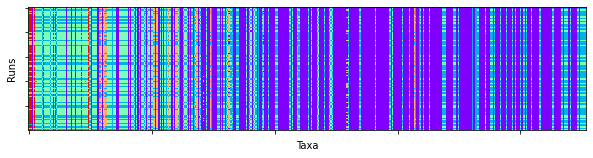

In [10]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_cdlib_all_gamma[1], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_cdlib_cons[1]

array([1, 2, 2, 2, 1, 2, 3, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 4, 1, 2, 1,
       2, 4, 5, 1, 1, 1, 1, 1, 1, 6, 1, 1, 1, 6, 1, 1, 6, 1, 1, 1, 1, 2,
       1, 1, 3, 5, 1, 2, 4, 6, 1, 1, 1, 1, 7, 2, 3, 1, 1, 1, 3, 3, 1, 1,
       1, 1, 5, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 6, 1, 1, 1, 1, 4, 3,
       1, 6, 3, 3, 1, 1, 4, 3, 1, 3, 1, 6, 1, 4, 3, 6, 3, 3, 6, 1, 3, 1,
       6, 1, 5, 1, 3, 4, 6, 7, 1, 3, 3, 3, 1, 5, 3, 3, 5, 1, 1, 4, 3, 5,
       6, 4, 6, 5, 1, 3, 1, 3, 5, 3, 1, 6, 6, 1, 3, 6, 3, 5, 6, 6, 6, 6,
       5, 4, 6, 5, 6, 7, 3, 5, 1, 3, 4, 4, 3, 3, 7, 7, 5, 3, 3, 6, 3, 7,
       6, 1, 6, 6, 4, 1, 6, 4, 5, 4, 6, 5, 6, 3, 7, 3, 6, 6, 3, 4, 6, 7,
       3, 7, 6, 4, 4, 3, 7, 6, 6, 1, 6, 1, 6, 3, 4, 4, 6, 1, 3, 3, 6, 3,
       4, 3, 3, 6, 3, 3, 6, 6, 4, 3, 1, 7, 3, 6, 6, 4, 1, 3, 6, 7, 6, 4,
       6, 6, 6, 4, 1, 4, 6, 3, 6, 3, 6, 6, 3, 3, 6, 6, 3, 3, 4, 7, 1, 6,
       3, 6, 6, 7, 3, 4, 4, 7, 6, 6, 6, 3, 1, 3, 6, 3, 3, 3, 4, 6, 3, 6,
       3, 6, 6, 6, 3, 2, 7, 6, 4, 6, 1, 6, 3, 6, 6,

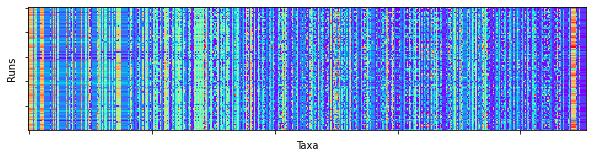

In [11]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_cdlib_all_gamma[2], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_cdlib_cons[2]

array([ 1,  2,  2,  2,  3,  2,  4,  3,  3,  3,  1,  2,  2,  1,  1,  3,  1,
        1,  4,  3,  2,  3,  2,  5,  6,  3,  1,  1,  3,  1,  3,  7,  1,  8,
        3,  1,  1,  3,  2,  1,  3,  3,  3,  2,  1,  3,  2,  3,  3,  2,  3,
        9,  1,  1,  1,  1, 10,  2,  4,  3,  1,  3,  4,  4,  3,  3,  3,  1,
        8,  3,  3,  1,  1,  1,  1,  1,  1,  1,  3,  3,  3,  9,  1, 10,  1,
        1,  5,  4,  1,  9,  4,  9,  3,  3,  5,  4,  1,  4,  3,  1,  3,  3,
        4,  9,  4,  4,  9,  3,  9,  1,  9,  1,  8,  1,  4,  3,  5, 11,  3,
        4,  4,  4,  3,  8,  4, 12,  4,  1,  1,  5,  4,  8,  1,  5,  4,  8,
        3,  4,  9,  4,  8,  4, 10,  9, 13,  1,  4,  9,  4,  8, 10,  9,  9,
       14,  8,  5, 15,  8,  9, 11,  4,  8,  3,  4,  5,  5,  1,  4,  9, 11,
        8,  4,  4,  9,  9, 11,  9,  1, 14,  9,  5,  1, 14,  5,  8,  9,  9,
        8, 15, 10, 11,  4, 11,  9,  4,  5,  9, 11,  9, 11, 16,  9,  5, 11,
        9,  9, 10, 10, 10, 10,  9,  4,  9,  5, 17,  1, 10,  4,  1,  4,  5,
       18,  4,  9,  4, 19

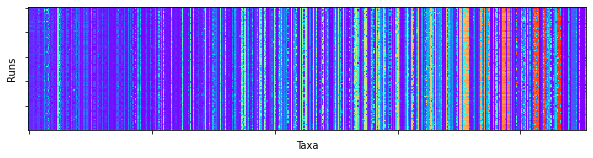

In [12]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_cdlib_all_gamma[3], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_cdlib_cons[3]

array([  1,   2,   2,   3,   4,   2,   2,   5,   6,   7,   3,   3,   3,
         8,   9,  10,  11,  12,   2,   4,   3,   4,   3,  13,  14,  15,
        16,  17,  18,  19,   4,  20,  21,  22,   4,  23,  19,  23,   2,
        24,  25,  26,   4,   2,  19,  26,   2,  27,  28,   2,  29,   4,
        23,  30,  23,  19,   4,   2,   1,   4,  23,   4,  31,   1,   4,
        32,   4,  33,  34,   4,   4,  33,  23,  23,  19,  19,   4,  19,
         4,  35,   4,  36,  19,   4,  19,  22,  13,  37,  33,  23,   1,
        36,   4,   4,  13,  37,  23,  37,   4,  23,  38,  29,   1,  31,
        37,  37,  36,   4,   1,  19,  39,  19,  40,  19,  37,   4,  41,
        31,   4,  37,   1,  37,   4,  34,  37,  42,   1,  19,  33,  29,
         1,  29,  43,  31,  44,  34,   4,  37,  36,   1,  29,   1,   4,
        36,  45,  19,  37,   1,  37,  29,   4,  36,  36,  36,  29,  29,
        46,  34,  36,  31,  47,  29,   4,  37,  29,  13,  24,  37,  31,
        31,  48,  31,  37,  49,  50,  31,  51,  19,  36,  31,   

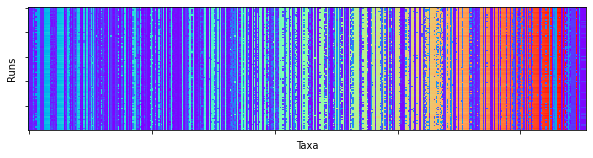

In [13]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_cdlib_all_gamma[4], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_cdlib_cons[4]

# Community discovery with python-louvain

In [14]:
# JSON representation of results
import community as community_louvain

# Louvain
# Can set resolution
# Can't set null model
# Can set random seed

louvain_pl_all_gamma=[None]*len(gamma_range)
louvain_pl_cons=[None]*len(gamma_range)
for y in range(len(gamma_range)):
    louvain_pl_allcoms=[None]*iter_range
    gamma_value = gamma_range[y]
    for x in range(iter_range):
        # x 
        random.seed(x)
        louvain_pl_com = community_louvain.best_partition(g, partition=None, \
                                                      weight='weight', \
                                                      resolution=gamma_value, \
                                                      # random_state=x, \
                                                      randomize=True)
        # np.array(list(louvain_pl_com.values()))
        louvain_pl_allcoms[x] = np.array(list(louvain_pl_com.values()))
    louvain_pl_all_gamma[y] = louvain_pl_allcoms
    louvain_pl_cons[y] = cluster.find_consensus(np.column_stack(louvain_pl_allcoms), \
                                                seed=1)   

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 3, 1, 3, 1,
       3, 3, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 3, 2,
       1, 2, 1, 2, 1, 1, 3, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 3, 2, 1,
       2, 3, 2, 1, 1, 2, 2, 2, 3, 2, 2, 2, 2, 1, 2, 2, 1, 1, 2, 2, 2, 2,
       3, 3, 2, 1, 2, 3, 2, 3, 1, 2, 3, 3, 1, 2, 2, 2, 3, 3, 2, 2, 2, 2,
       2, 2, 2, 2, 3, 2, 2, 3, 1, 3, 2, 1, 2, 2, 3, 2, 2, 2, 2, 3, 2, 2,
       2, 2, 2, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 2, 1, 2, 2, 2, 1,
       3, 2, 2, 2, 2, 2, 2, 2, 3, 2, 1, 2, 2, 2, 2, 3, 1, 2, 2, 2, 2, 3,
       2, 2, 2, 3, 1, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 1, 2, 2, 2, 2,

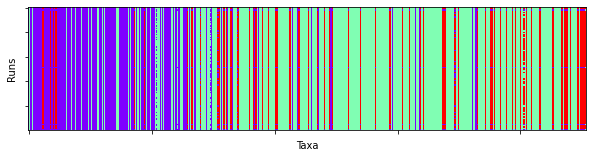

In [15]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_pl_all_gamma[0], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_pl_cons[0] 

array([1, 2, 2, 3, 1, 2, 1, 1, 1, 1, 1, 4, 2, 1, 1, 1, 1, 1, 4, 1, 2, 1,
       2, 4, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 4, 3, 1, 1, 1, 1, 3, 3, 5, 1, 3, 1, 5, 5, 1, 1,
       1, 1, 4, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 1, 1, 3, 1, 3, 1, 1, 4, 3,
       1, 3, 4, 3, 1, 1, 4, 5, 3, 5, 1, 3, 1, 1, 5, 3, 5, 5, 3, 1, 3, 1,
       3, 1, 4, 1, 5, 1, 3, 3, 1, 3, 5, 5, 1, 4, 3, 3, 4, 1, 1, 4, 3, 4,
       3, 4, 3, 4, 1, 5, 3, 5, 4, 3, 3, 3, 3, 1, 3, 3, 5, 4, 3, 3, 3, 3,
       4, 4, 3, 4, 3, 4, 3, 4, 1, 5, 4, 4, 4, 3, 3, 4, 4, 4, 3, 3, 3, 3,
       3, 1, 3, 3, 4, 1, 3, 4, 1, 4, 3, 4, 3, 3, 4, 5, 3, 3, 3, 4, 3, 3,
       3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 3, 1, 3, 3, 3, 5,
       4, 3, 3, 3, 3, 3, 3, 3, 4, 3, 1, 3, 3, 3, 3, 4, 1, 3, 3, 3, 3, 4,
       3, 3, 3, 4, 1, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3,
       3, 3, 3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 1, 3, 3, 3, 3,

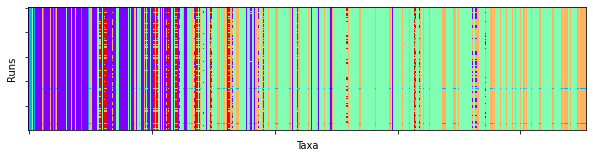

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_pl_all_gamma[1], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_pl_cons[1]

array([1, 2, 2, 2, 1, 2, 3, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 4, 1, 2, 1,
       2, 4, 3, 1, 1, 1, 1, 1, 1, 5, 1, 1, 1, 6, 1, 1, 6, 1, 1, 1, 1, 2,
       1, 1, 3, 3, 1, 2, 4, 6, 1, 1, 1, 1, 6, 2, 3, 1, 1, 1, 3, 3, 1, 1,
       1, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 6, 1, 1, 1, 1, 4, 7,
       1, 6, 3, 7, 1, 1, 4, 3, 1, 3, 1, 6, 1, 4, 3, 6, 3, 3, 6, 1, 7, 1,
       6, 1, 3, 1, 3, 4, 6, 5, 1, 7, 3, 3, 1, 3, 7, 7, 3, 1, 1, 4, 7, 3,
       6, 4, 6, 3, 1, 3, 1, 3, 3, 3, 1, 6, 5, 1, 7, 6, 3, 3, 6, 6, 6, 6,
       3, 4, 6, 3, 6, 5, 7, 3, 1, 7, 4, 4, 3, 7, 5, 5, 3, 3, 7, 6, 7, 5,
       6, 1, 6, 6, 4, 1, 6, 4, 3, 4, 6, 3, 6, 7, 5, 7, 6, 6, 7, 4, 6, 5,
       7, 5, 6, 4, 4, 7, 6, 6, 6, 1, 6, 1, 6, 7, 4, 4, 6, 1, 7, 7, 6, 3,
       4, 7, 7, 6, 7, 7, 6, 6, 4, 3, 1, 5, 7, 6, 6, 4, 1, 7, 6, 5, 6, 4,
       6, 6, 6, 4, 1, 4, 6, 3, 6, 7, 6, 5, 7, 7, 6, 6, 7, 7, 4, 5, 1, 6,
       7, 6, 6, 5, 7, 4, 4, 5, 6, 6, 6, 7, 1, 7, 6, 7, 7, 7, 4, 6, 7, 6,
       7, 6, 6, 6, 7, 2, 5, 6, 4, 6, 1, 6, 7, 6, 6,

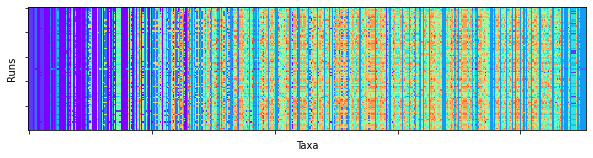

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_pl_all_gamma[2], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_pl_cons[2]

array([ 1,  2,  2,  2,  3,  2,  4,  3,  3,  3,  1,  2,  2,  1,  1,  3,  1,
        1,  4,  3,  2,  3,  2,  5,  1,  3,  1,  1,  3,  1,  3,  6,  1,  7,
        3,  1,  1,  3,  2,  1,  3,  3,  3,  2,  1,  3,  2,  3,  3,  2,  3,
        8,  1,  1,  1,  1,  9,  2,  4,  3,  1,  3,  4,  4,  3,  3,  3,  1,
        7,  3,  3,  1,  1,  1,  1,  1,  3,  1,  3,  3,  3,  8,  1,  9,  1,
        1,  5,  4,  1, 10,  4,  8,  3,  3,  5,  4,  1,  4,  3,  1,  3,  3,
        4,  8,  4,  4,  8,  3,  8,  1,  3,  1,  7,  1,  4,  3,  3, 10,  3,
        4,  4,  4,  3,  7,  4, 11,  4,  1,  1,  5,  4,  7,  1,  5, 10,  7,
        3,  4,  8,  4,  7,  4,  9,  8, 12,  1,  4,  8,  4,  7,  9,  8,  8,
       13,  7,  5, 14,  7,  8, 10,  4,  7,  3,  4,  5,  5,  1,  4,  8, 10,
        7,  4,  4,  8,  8, 10,  8,  1, 13,  8,  5,  1, 13,  5,  7,  8,  8,
        7, 14,  9, 10,  4, 10,  8,  4,  5,  8, 10,  8, 10,  8,  8,  5, 10,
        8,  8,  9,  9,  9,  9,  8,  4,  8,  5, 15,  1,  9,  4,  1,  4,  5,
       16,  4,  8,  4, 17

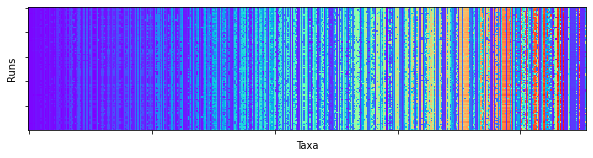

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_pl_all_gamma[3], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_pl_cons[3]

array([  1,   2,   2,   3,   4,   2,   5,   1,   1,   6,   3,   3,   3,
         7,   8,   9,  10,  11,   2,   4,   3,   4,   3,  12,  13,  14,
        15,  16,  17,  18,   4,  19,  20,   1,   4,  21,  18,   1,   2,
        22,   4,  23,   4,   2,  18,  23,   2,  24,  25,   2,   1,   4,
         1,  26,   1,  18,   4,   2,   5,   4,  21,   4,  27,   5,   4,
        28,   4,  29,  30,   4,   4,  29,  21,  21,  18,  18,   4,  18,
         4,  31,   4,  27,  18,   4,  18,   1,  12,  32,  29,  21,   5,
        33,   4,   4,  12,  32,  21,  32,   4,  21,  34,   1,   5,  27,
        32,  32,  33,   4,  33,  18,   4,  18,  35,  18,  32,   4,  36,
        27,   4,  32,   5,  32,   4,  30,  32,  37,   5,  18,  29,   1,
         5,  38,  21,  27,  21,  30,   4,  32,  33,   5,   1,   5,   4,
        33,  39,  18,  32,  40,  32,   1,  41,  33,  33,  33,  38,   1,
        42,  30,  33,  27,  43,   1,   4,  32,   1,  12,  22,  32,  27,
        27,  44,  27,  32,  45,  46,  27,  47,  18,  33,  27,   

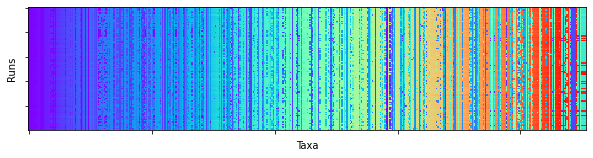

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(louvain_pl_all_gamma[4], cmap='rainbow', interpolation='None')
ax.set(xlabel='Taxa', ylabel='Runs', \
       xticklabels=[], yticklabels=[])
louvain_pl_cons[4]

# Community discovery with louvain by Traag (RBC)

In [20]:
import louvain as lou

louvain_lou_rbc_all_gamma=[None]*len(gamma_range)
louvain_lou_rbc_cons=[None]*len(gamma_range)
for y in range(len(gamma_range)):
    louvain_lou_rbc_allcoms=[None]*iter_range
    gamma_value = gamma_range[y]
    for x in range(iter_range):
        # x 
        random.seed(x)
        louvain_lou_rbc_com = lou.find_partition(g2, \
                                          partition_type = lou.RBConfigurationVertexPartition, \
                                           initial_membership=None, \
                                           weights="weight", \
                                          seed=x,
                                           resolution_parameter = gamma_value)
        # np.array(list(louvain_lou_rbc_com.values()))
        louvain_lou_rbc_allcoms[x] = np.array(louvain_lou_rbc_com.membership)
    louvain_lou_rbc_all_gamma[y] = louvain_lou_rbc_allcoms
    louvain_lou_rbc_cons[y] = cluster.find_consensus(np.column_stack(louvain_lou_rbc_allcoms), \
                                                seed=1)

<ipython-input-20-7396a690a13f>:1: DeprecationWarning: This package has been superseded by the `leidenalg` package and will no longer be maintained. Please upgrade to the `leidenalg` package.
  import louvain as lou


array([1, 2, 2, 2, 1, 2, 3, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 4, 1, 2, 1,
       2, 4, 5, 1, 1, 1, 1, 1, 1, 6, 1, 1, 1, 6, 1, 1, 6, 1, 1, 1, 1, 2,
       1, 1, 3, 5, 1, 2, 4, 6, 1, 1, 1, 1, 6, 2, 3, 1, 1, 1, 3, 3, 1, 1,
       1, 1, 5, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 6, 1, 1, 1, 1, 4, 3,
       1, 6, 3, 3, 1, 1, 4, 3, 1, 3, 1, 6, 1, 4, 3, 6, 3, 3, 6, 1, 3, 1,
       6, 1, 5, 1, 3, 4, 6, 2, 1, 3, 3, 3, 1, 5, 3, 3, 5, 1, 1, 4, 3, 5,
       6, 4, 6, 5, 1, 3, 1, 3, 5, 3, 1, 6, 6, 1, 3, 6, 3, 5, 6, 6, 6, 6,
       5, 4, 6, 5, 6, 2, 3, 5, 1, 3, 4, 4, 5, 3, 2, 2, 5, 3, 3, 6, 3, 2,
       6, 1, 6, 6, 4, 1, 6, 4, 5, 4, 6, 5, 6, 6, 2, 3, 6, 6, 3, 4, 6, 2,
       3, 2, 6, 4, 4, 3, 2, 6, 6, 1, 6, 1, 6, 3, 4, 4, 6, 1, 3, 3, 6, 3,
       4, 3, 3, 6, 3, 3, 6, 6, 4, 3, 1, 2, 3, 6, 6, 4, 1, 3, 6, 2, 6, 4,
       6, 6, 6, 4, 1, 4, 6, 3, 6, 3, 6, 6, 3, 3, 6, 6, 3, 3, 4, 2, 1, 6,
       3, 6, 6, 2, 3, 4, 4, 2, 6, 6, 6, 3, 1, 3, 6, 3, 3, 3, 4, 6, 3, 6,
       3, 6, 6, 6, 3, 2, 2, 6, 4, 6, 1, 6, 3, 6, 6,

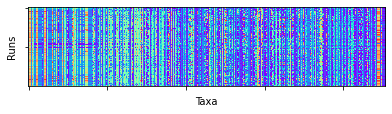

In [21]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_rbc_all_gamma[0], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_rbc_cons[0]

array([1, 2, 2, 3, 1, 2, 1, 1, 1, 1, 1, 4, 2, 1, 1, 1, 1, 1, 4, 1, 2, 1,
       2, 4, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 4, 3, 1, 1, 1, 1, 3, 3, 5, 1, 3, 1, 5, 5, 1, 1,
       1, 1, 4, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 1, 1, 3, 1, 3, 1, 1, 4, 3,
       1, 3, 4, 3, 1, 1, 4, 5, 3, 5, 1, 3, 1, 1, 5, 3, 5, 5, 3, 1, 3, 1,
       3, 1, 4, 1, 5, 1, 3, 3, 1, 3, 5, 5, 1, 4, 3, 3, 4, 1, 1, 4, 3, 4,
       3, 4, 3, 4, 1, 5, 3, 5, 4, 3, 3, 3, 3, 1, 3, 3, 5, 4, 3, 3, 3, 3,
       4, 4, 3, 4, 3, 4, 3, 4, 1, 5, 4, 4, 4, 3, 3, 4, 4, 4, 3, 3, 3, 3,
       3, 1, 3, 3, 4, 1, 3, 4, 1, 4, 3, 4, 3, 3, 4, 5, 3, 3, 3, 4, 3, 3,
       3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 3, 1, 3, 3, 3, 5,
       4, 3, 3, 3, 3, 3, 3, 3, 4, 3, 1, 3, 3, 3, 3, 4, 1, 3, 3, 3, 3, 4,
       3, 3, 3, 4, 1, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3,
       3, 3, 3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 1, 3, 3, 3, 3,

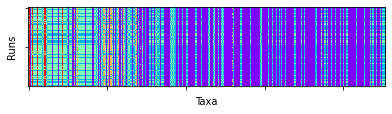

In [22]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_rbc_all_gamma[1], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_rbc_cons[1]

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 3, 1, 3, 1,
       3, 3, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 3, 2,
       1, 2, 1, 2, 1, 1, 3, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 3, 2, 1,
       2, 3, 2, 1, 1, 2, 2, 2, 3, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2,
       3, 3, 2, 1, 2, 3, 2, 3, 1, 2, 3, 3, 1, 2, 2, 2, 3, 3, 2, 2, 2, 2,
       2, 2, 2, 2, 3, 2, 2, 3, 1, 3, 2, 1, 2, 2, 3, 2, 2, 2, 2, 3, 2, 2,
       2, 2, 2, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 2, 1, 2, 2, 2, 1,
       3, 2, 2, 2, 2, 2, 2, 2, 3, 2, 1, 2, 2, 2, 2, 3, 1, 2, 2, 2, 2, 3,
       2, 2, 2, 3, 1, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 1, 2, 2, 2, 2,

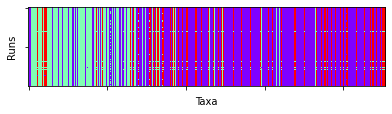

In [23]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_rbc_all_gamma[2], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_rbc_cons[2]

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2,
       1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,

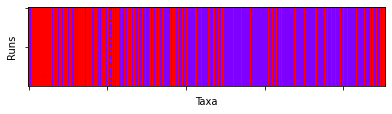

In [24]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_rbc_all_gamma[3], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_rbc_cons[3]

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2,
       1, 1, 2, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,

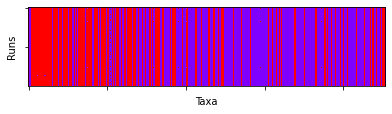

In [25]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_rbc_all_gamma[4], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_rbc_cons[4]

# Community discovery with louvain by Traag (CPM)

In [26]:
louvain_lou_cpm_all_gamma=[None]*len(gamma_range)
louvain_lou_cpm_cons=[None]*len(gamma_range)
for y in range(len(gamma_range)):
    louvain_lou_cpm_allcoms=[None]*iter_range
    
    # Note different gamma_value ranges
    gamma_value = gamma_range[y]/200
    for x in range(iter_range):
        # x 
        random.seed(x)
        louvain_lou_cpm_com = lou.find_partition(g2, \
                                          partition_type = lou.CPMVertexPartition, \
                                           initial_membership=None, \
                                           weights="weight", \
                                          seed=x,
                                           resolution_parameter = gamma_value)
        # np.array(list(louvain_lou_cpm_com.values()))
        louvain_lou_cpm_allcoms[x] = np.array(louvain_lou_cpm_com.membership)
    louvain_lou_cpm_all_gamma[y] = louvain_lou_cpm_allcoms
    louvain_lou_cpm_cons[y] = cluster.find_consensus(np.column_stack(louvain_lou_cpm_allcoms), \
                                                seed=1) 

array([ 1,  2,  2,  3,  1,  2,  1,  1,  1,  1,  4,  4,  4,  1,  1,  1,  1,
        1,  2,  1,  4,  1,  4,  4,  1,  1,  1,  1,  1,  1,  1,  3,  1,  1,
        1,  5,  6,  1,  2,  1,  1,  1,  1,  2,  1,  1,  2,  1,  1,  2,  7,
        3,  1,  1,  1,  1,  8,  9,  1,  1, 10, 11,  9,  1,  1,  1, 12,  1,
        1,  1,  1,  1, 10,  3,  6,  6,  1,  1,  1,  1,  1,  3,  1,  8,  6,
        1,  9,  3,  1,  9,  1,  3,  1,  1,  9,  1, 10,  1,  1,  3,  1,  1,
       13,  3,  9,  9,  3,  1,  3,  1,  3,  6,  1,  6,  1,  1,  3,  9,  1,
        9,  9,  9,  1,  1,  9,  3,  1,  1,  1,  9, 13,  1,  3,  9,  3, 14,
       12,  9, 15, 13,  1, 13, 11,  3,  3,  6,  9,  3,  9,  1,  3,  3,  9,
        3,  1,  9,  3,  7,  9,  9,  3,  9,  1,  9,  9,  9, 15,  9,  3,  9,
        1,  9,  9,  3,  3,  3,  3,  6,  3,  3,  9,  6,  3,  9,  1,  9,  3,
        1,  3,  3,  9,  9,  3,  3,  9,  9, 16,  9, 17,  9,  3,  9,  9,  9,
        3,  3,  3,  3, 14,  8,  3,  3,  9,  9,  3,  1,  3,  3,  3, 13,  9,
        3,  9,  3,  3,  3

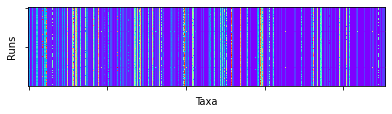

In [27]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_cpm_all_gamma[0], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_cpm_cons[0]

array([ 1,  2,  2,  3,  1,  2,  1,  1,  1,  1,  1,  1,  2,  1,  1,  1,  1,
        1,  2,  1,  2,  1,  2,  1,  1,  1,  1,  1,  1,  1,  1,  3,  1,  1,
        1,  3,  4,  1,  2,  1,  1,  1,  1,  2,  1,  1,  1,  1,  1,  2,  5,
        3,  1,  1,  1,  1,  3,  6,  1,  1,  4,  7,  8,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  4,  3,  4,  4,  1,  1,  1,  1,  1,  3,  1,  3,  1,
        1,  1,  3,  1,  3,  1,  3,  1,  1,  1,  1,  4,  1,  1,  3,  1,  1,
        1,  3,  9,  9,  3,  1,  3,  1,  3,  4,  1,  1,  1,  1,  3,  8,  1,
        9,  1,  9,  1,  1,  3,  3,  1,  1,  1,  1,  3,  1,  3,  1,  3,  1,
        1,  9,  4, 10,  1, 10,  7,  3,  3,  4,  9,  3,  9,  1,  3,  3, 11,
        3,  1,  1,  3,  1, 11,  1,  3,  1,  1,  9,  1,  1,  4,  3,  3,  1,
        1,  1,  9,  3,  3,  3,  3,  4,  3,  3,  1,  4,  3,  1,  1,  1,  3,
        1,  3,  3,  1,  9,  3,  3,  3,  1,  3,  3, 11,  3,  3,  1,  1,  8,
        3,  3,  3,  3, 12,  3,  3,  3,  1,  1,  3,  1,  3,  3,  3,  1,  1,
        3,  3,  3,  3,  3

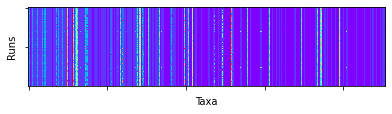

In [28]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_cpm_all_gamma[1], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_cpm_cons[1]

array([ 1,  2,  1,  2,  1,  1,  1,  1,  1,  1,  1,  1,  3,  1,  1,  1,  1,
        1,  1,  1,  3,  1,  3,  1,  1,  1,  1,  1,  1,  1,  1,  2,  1,  1,
        1,  2,  1,  1,  2,  1,  1,  1,  1,  3,  1,  1,  1,  1,  1,  4,  1,
        2,  1,  1,  1,  1,  2,  5,  1,  1,  6,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  6,  2,  1,  1,  1,  1,  1,  1,  1,  2,  1,  2,  1,
        1,  1,  2,  1,  2,  1,  2,  1,  1,  1,  1,  2,  1,  1,  2,  1,  1,
        1,  2,  1,  2,  2,  1,  2,  1,  2,  1,  1,  1,  1,  1,  2,  7,  1,
        2,  1,  1,  1,  1,  2,  2,  1,  1,  1,  1,  2,  1,  2,  1,  2,  1,
        1,  2,  2,  2,  1,  2,  8,  2,  2,  1,  2,  2,  1,  1,  2,  2,  2,
        2,  1,  1,  2,  1,  2,  1,  2,  1,  1,  2,  1,  1,  1,  2,  2,  1,
        1,  1,  2,  2,  2,  2,  2,  1,  2,  2,  1,  2,  2,  1,  1,  1,  2,
        1,  2,  2,  1,  2,  2,  2,  2,  1,  2,  2,  2,  2,  2,  1,  1,  2,
        2,  2,  2,  2,  2,  2,  2,  2,  1,  1,  2,  1,  2,  2,  2,  1,  1,
        2,  2,  2,  2,  2

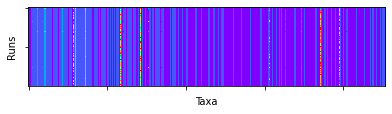

In [29]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_cpm_all_gamma[2], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_cpm_cons[2]

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 1, 2, 2, 1, 2, 2, 1, 1, 2, 2, 2, 2,
       1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2,

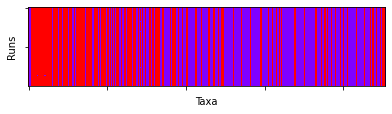

In [30]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_cpm_all_gamma[3], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_cpm_cons[3]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

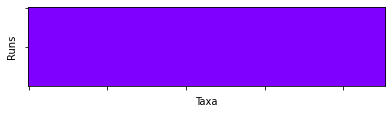

In [31]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_cpm_all_gamma[4], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_cpm_cons[4]

# Community discovery with leidenalg (RBC)

In [32]:
# Leiden (RBC) - resolution parameter = 1 should be identical to modularity
# Can set resolution
# Can set null model
# Can't set random seed but can set initial membership (default = singleton partitions)
# optimiser = la.Optimiser()
# leiden_la_rbc_com = la.RBConfigurationVertexPartition(g2, initial_membership=None, \
#                                                       weights="weight", \
#                                                       node_sizes=[1]*532, \
#                                                       resolution_parameter=1.0)
# optimiser.optimise_partition(leiden_la_rbc_com)
# len(set(leiden_la_rbc_com.membership))

In [33]:
# Can set resolution
# Can set null model
# Can set seed

leiden_la_rbc_all_gamma=[None]*len(gamma_range)
leiden_la_rbc_cons=[None]*len(gamma_range)
for y in range(len(gamma_range)):
    leiden_la_rbc_allcoms=[None]*iter_range
    gamma_value = gamma_range[y]
    for x in range(iter_range):
        # x 
        random.seed(x)
        leiden_la_rbc_com = la.find_partition(g2, \
                                          partition_type = la.RBConfigurationVertexPartition, \
                                           initial_membership=None, \
                                           weights="weight", \
                                           n_iterations=-1, 
                                           max_comm_size=0, 
                                          seed=x,
                                           resolution_parameter = gamma_value)
        # np.array(list(leiden_la_rbc_com.values()))
        leiden_la_rbc_allcoms[x] = np.array(leiden_la_rbc_com.membership)
    leiden_la_rbc_all_gamma[y] = leiden_la_rbc_allcoms
    leiden_la_rbc_cons[y] = cluster.find_consensus(np.column_stack(leiden_la_rbc_allcoms), \
                                                seed=1) 

array([1, 2, 2, 2, 1, 2, 3, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 4, 1, 2, 1,
       2, 4, 3, 1, 1, 1, 1, 1, 1, 5, 1, 1, 1, 5, 1, 1, 5, 1, 1, 1, 1, 2,
       1, 1, 3, 3, 1, 2, 4, 5, 1, 1, 1, 1, 1, 2, 3, 1, 1, 1, 3, 3, 1, 1,
       1, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 5, 1, 1, 1, 1, 4, 6,
       1, 5, 3, 6, 1, 1, 4, 3, 1, 3, 1, 5, 1, 4, 3, 5, 3, 6, 5, 1, 6, 1,
       5, 1, 3, 1, 3, 4, 5, 7, 1, 6, 3, 6, 1, 3, 6, 6, 3, 1, 1, 4, 6, 3,
       5, 4, 5, 3, 1, 6, 1, 3, 3, 3, 1, 5, 5, 1, 6, 5, 3, 3, 5, 5, 5, 5,
       3, 4, 5, 3, 5, 7, 6, 4, 1, 6, 4, 4, 3, 6, 7, 7, 3, 3, 6, 5, 6, 7,
       5, 1, 5, 5, 4, 1, 5, 4, 3, 4, 5, 3, 5, 5, 7, 6, 5, 5, 6, 4, 5, 7,
       6, 7, 5, 4, 4, 7, 5, 5, 5, 1, 5, 1, 5, 6, 4, 4, 5, 1, 6, 6, 5, 3,
       4, 6, 6, 5, 6, 6, 5, 5, 4, 3, 1, 7, 6, 5, 5, 4, 1, 6, 5, 7, 5, 4,
       5, 5, 5, 4, 1, 4, 1, 6, 5, 6, 5, 5, 6, 6, 5, 5, 6, 6, 4, 7, 1, 5,
       6, 5, 7, 7, 6, 4, 4, 7, 5, 5, 5, 6, 1, 6, 5, 6, 6, 6, 4, 5, 6, 5,
       6, 5, 5, 5, 6, 2, 7, 5, 4, 5, 1, 5, 6, 5, 5,

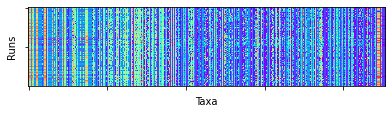

In [34]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_rbc_all_gamma[0], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_rbc_cons[0]

array([1, 2, 2, 3, 1, 2, 1, 1, 1, 1, 1, 4, 2, 1, 1, 1, 1, 1, 4, 1, 2, 1,
       2, 4, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 4, 3, 1, 1, 1, 1, 3, 3, 4, 1, 3, 1, 5, 5, 1, 1,
       1, 1, 4, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 1, 1, 3, 1, 3, 1, 1, 4, 3,
       1, 3, 4, 3, 1, 1, 4, 5, 3, 5, 1, 3, 1, 1, 5, 3, 5, 5, 3, 1, 3, 1,
       3, 1, 4, 1, 5, 1, 3, 3, 1, 3, 5, 5, 1, 4, 3, 3, 4, 1, 1, 4, 3, 4,
       3, 4, 3, 4, 1, 5, 3, 5, 4, 3, 1, 3, 3, 1, 3, 3, 5, 4, 3, 3, 3, 3,
       4, 4, 3, 4, 3, 4, 3, 4, 1, 5, 4, 4, 1, 3, 3, 4, 4, 4, 3, 3, 3, 3,
       3, 1, 3, 3, 4, 1, 3, 4, 1, 4, 3, 4, 3, 3, 4, 5, 3, 3, 3, 4, 3, 3,
       3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 3, 1, 3, 3, 3, 5,
       4, 3, 3, 3, 3, 3, 3, 3, 4, 3, 1, 3, 3, 3, 3, 4, 1, 3, 3, 3, 3, 4,
       3, 3, 3, 4, 1, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3,
       3, 3, 3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 1, 3, 3, 3, 3,

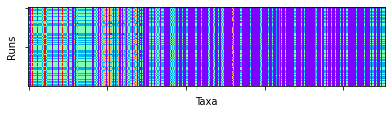

In [35]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_rbc_all_gamma[1], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_rbc_cons[1]

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2,
       1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2,

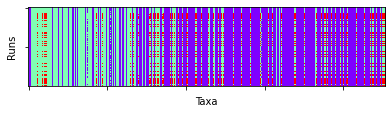

In [36]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_rbc_all_gamma[2], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_rbc_cons[2]

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2,
       1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2,

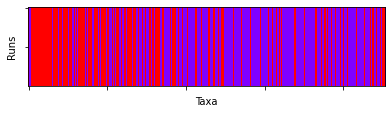

In [37]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_rbc_all_gamma[3], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_rbc_cons[3]

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2,
       1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2,

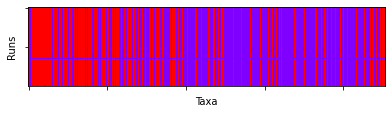

In [38]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_rbc_all_gamma[4], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_rbc_cons[4]

# Community discovery with leidenalg (cpm)

In [39]:
leiden_la_cpm_all_gamma=[None]*len(gamma_range)
leiden_la_cpm_cons=[None]*len(gamma_range)
for y in range(len(gamma_range)):
    leiden_la_cpm_allcoms=[None]*iter_range
    
    # Note different gamma_value ranges
    gamma_value = gamma_range[y]/200
    for x in range(iter_range):
        # x 
        random.seed(x)
        leiden_la_cpm_com = la.find_partition(g2, \
                                          partition_type = la.CPMVertexPartition, \
                                           initial_membership=None, \
                                           weights="weight", \
                                           n_iterations=-1, 
                                           max_comm_size=0, 
                                          seed=x,
                                           resolution_parameter = gamma_value)
        # np.array(list(leiden_la_cpm_com.values()))
        leiden_la_cpm_allcoms[x] = np.array(leiden_la_cpm_com.membership)
    leiden_la_cpm_all_gamma[y] = leiden_la_cpm_allcoms
    leiden_la_cpm_cons[y] = cluster.find_consensus(np.column_stack(leiden_la_cpm_allcoms), \
                                                seed=1) 

array([ 1,  2,  2,  3,  1,  2,  1,  1,  1,  1,  4,  4,  4,  1,  1,  1,  1,
        1,  2,  1,  4,  1,  4,  5,  1,  1,  1,  1,  1,  1,  1,  3,  1,  1,
        1,  6,  7,  1,  2,  1,  1,  1,  1,  2,  1,  1,  2,  1,  1,  2,  8,
        3,  1,  1,  1,  1,  9,  2,  1,  1, 10, 11, 12,  1,  1,  1, 13,  1,
        1,  1,  1,  1, 10,  3,  7,  7,  1,  1,  1,  1,  1,  3,  1,  9,  7,
        1, 12,  3,  1,  2,  1,  3,  1,  1, 12,  1, 10,  1,  1,  3,  1,  1,
       14,  3, 15, 15,  3,  1,  3,  1,  3,  7,  1,  7,  1,  1,  3, 12,  1,
       15, 15, 15,  1,  1, 15,  3,  1,  1,  1, 12, 14,  1,  3, 12,  3, 16,
       13, 15, 17, 14,  1, 14, 11,  3,  3,  7, 15,  3, 15,  1,  3,  3,  5,
        3,  1, 12,  3,  8,  5, 12,  3, 12,  1, 15, 12, 12, 17, 15,  3, 12,
        1, 12, 15,  3,  3,  3,  3,  7,  3,  3, 12,  7,  3, 12,  1, 12,  3,
        1,  3,  3, 12, 15,  3,  3, 15, 12, 18, 12, 19, 12,  3, 12, 12, 12,
        3,  3,  3,  3, 16,  9,  3,  3, 12, 12,  3,  1,  3,  3,  3, 14, 12,
        3, 15,  3,  3,  3

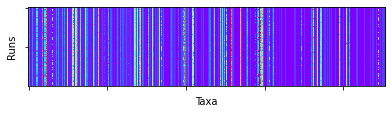

In [40]:
# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_cpm_all_gamma[0], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_cpm_cons[0]

array([ 1,  2,  2,  3,  1,  2,  1,  1,  1,  1,  2,  2,  2,  1,  1,  1,  1,
        1,  2,  1,  2,  1,  2,  4,  1,  1,  1,  1,  1,  1,  1,  3,  1,  1,
        1,  3,  5,  1,  2,  1,  1,  1,  1,  2,  1,  1,  2,  1,  1,  2,  6,
        3,  1,  1,  1,  1,  3,  7,  1,  1,  5,  8,  9,  1,  1,  1, 10,  1,
        1,  1,  1,  1,  5,  3,  5,  5,  1,  1,  1,  1,  1,  3,  1,  3,  1,
        1,  1,  3,  1,  3,  1,  3,  1,  1,  1,  1,  5,  1,  1,  3,  1,  1,
        1,  3, 11, 11,  3,  1,  3,  1,  3,  5,  1,  5,  1,  1,  3,  9,  1,
       11,  1, 11,  1,  1, 11,  3,  1,  1,  1,  1,  3,  1,  3,  1,  3,  1,
       10, 11, 10,  9,  1,  9,  8,  3,  3,  5, 11,  3, 11,  1,  3,  3, 10,
        3,  1,  1,  3,  1, 10,  1,  3,  1,  1, 11,  1,  1, 10,  3,  3,  9,
        1,  1, 11,  3,  3,  3,  3,  5,  3,  3,  1,  5,  3,  1,  1,  1,  3,
        1,  3,  3,  1, 11,  3,  3,  3,  1,  3,  3, 12,  3,  3,  1,  1,  9,
        3,  3,  3,  3, 13,  3,  3,  3,  1,  1,  3,  1,  3,  3,  3,  1,  1,
        3,  3,  3,  3,  3

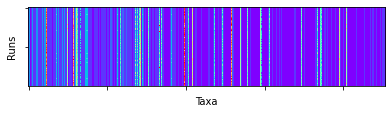

In [41]:
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_cpm_all_gamma[1], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_cpm_cons[1]

array([1, 2, 3, 2, 1, 3, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 1, 3, 1, 3, 1,
       3, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 3,
       1, 1, 1, 1, 1, 3, 1, 2, 1, 1, 1, 1, 2, 4, 1, 1, 5, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 5, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 6, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 7, 2, 2, 1, 2, 2, 1, 1, 2, 2, 6, 2,
       1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2,

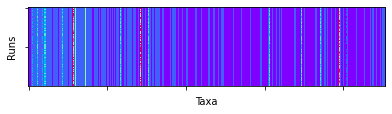

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_cpm_all_gamma[2], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_cpm_cons[2]

array([1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 1,
       2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 1, 1, 2, 2, 2, 2,
       1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2,

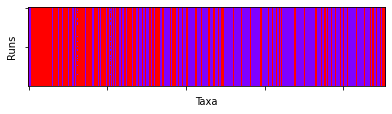

In [43]:
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_cpm_all_gamma[3], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_cpm_cons[3]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

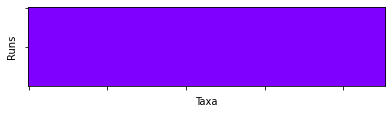

In [44]:
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_cpm_all_gamma[4], cmap='rainbow', interpolation='None')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_cpm_cons[4]

# Community discovery with ig (modularity)

In [45]:
# Leiden
# Finds the community structure of the graph using the Leiden algorithm of Traag, van Eck & Waltman.
# Can set resolution
# Can set null model (but can only choose CPM vs. modularity = Newman-Girvan)
# Can't set random seed, but can set initial membership (default = singleton partitions)
# beta - parameter affecting the randomness in the Leiden algorithm. \
# This affects only the refinement step of the algorithm.

In [46]:
# leiden_ig_mod_all_gamma=[None]*len(gamma_range)
# leiden_ig_mod_cons=[None]*len(gamma_range)
# for y in range(len(gamma_range)):
#     leiden_ig_mod_allcoms=[None]*iter_range
#     gamma_value = gamma_range[y]
#     for x in range(iter_range):
#         # x
#         random.seed(x)
#         leiden_ig_mod_com = ig.Graph.community_leiden(g2, objective_function="modularity", \
#                                                   weights="weight", \
#                                                   resolution_parameter=gamma_value, \
#                                                   beta=0.01, \
#                                                   initial_membership=None, \
#                                                   n_iterations=1, \
#                                                   node_weights=None)
#         leiden_ig_mod_allcoms[x] = np.array(leiden_ig_mod_com.membership)
#     leiden_ig_mod_all_gamma[y] = leiden_ig_mod_allcoms
#     leiden_ig_mod_cons[y] = cluster.find_consensus(np.column_stack(leiden_ig_mod_allcoms), \
#                                                 seed=1) 

In [47]:
# Create plot of membership by runs ~ taxa
# fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
# ax.imshow(leiden_ig_mod_all_gamma[0], cmap='rainbow', interpolation='none')
# ax.set(ylabel='Runs', xlabel='Taxa', \
#        xticklabels=[], yticklabels=[])
# leiden_ig_mod_cons[0]

# Community discovery with ig (cpm)

In [48]:
# leiden_ig_cpm_all_gamma=[None]*len(gamma_range)
# leiden_ig_cpm_cons=[None]*len(gamma_range)
# for y in range(len(gamma_range)):
#     leiden_ig_cpm_allcoms=[None]*iter_range
#     gamma_value = gamma_range[y]
#     for x in range(iter_range):
#         # x 
#         random.seed(x)
#         leiden_ig_cpm_com = ig.Graph.community_leiden(g2, objective_function="CPM", \
#                                                   weights="weight", \
#                                                   resolution_parameter=gamma_value/200, \
#                                                   beta=0.01, \
#                                                   initial_membership=None, \
#                                                   n_iterations=1, \
#                                                   node_weights=None)
#         # np.array(list(leiden_ig_cpm_com.values()))
#         leiden_ig_cpm_allcoms[x] = np.array(leiden_ig_cpm_com.membership)
#     leiden_ig_cpm_all_gamma[y] = leiden_ig_cpm_allcoms
#     leiden_ig_cpm_cons[y] = cluster.find_consensus(np.column_stack(leiden_ig_cpm_allcoms), \
#                                                 seed=1) 

In [49]:
# # Create plot of membership by runs ~ taxa
# fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
# ax.imshow(leiden_ig_cpm_all_gamma[0], cmap='rainbow', interpolation='None')
# ax.set(ylabel='Runs', xlabel='Taxa', \
#        xticklabels=[], yticklabels=[])
# leiden_ig_cpm_cons[0]

# Export output to csv

In [50]:
import csv

In [51]:
method_range =  ("louvain_cdlib", "louvain_pl",
                 "louvain_lou_rbc", "louvain_lou_cpm",
                "leiden_la_rbc", "leiden_la_cpm")

for y in method_range:
    for x in range(len(gamma_range)):
        # gamma_value = gamma_range[x]
        with open(output_dir + str(y) + "_all_gamma_" + str(x) + ".coast.sick.csv", "w") as f:
            csvwriter = csv.writer(f)
            csvwriter.writerows(globals()[str(y) + "_all_gamma"][x])
        np.savetxt(output_dir + str(y) + "_cons_" + str(x) + ".coast.sick.csv", \
               (globals()[str(y) + "_cons"][x]-1).astype(int), fmt="%i", delimiter=",")

In [52]:
# for x in range(len(gamma_range)):
#     with open(output_dir + "louvain_cdlib_all_gamma_" + str(x) + ".csv", "w") as f:
#         csvwriter = csv.writer(f)
#         csvwriter.writerows(louvain_cdlib_all_gamma[x])
#     np.savetxt(output_dir + "louvain_cdlib_cons_" + str(x) + ".csv", \
#            (louvain_cdlib_cons[x]-1).astype(int), fmt="%i", delimiter=",")

In [53]:
# for x in range(len(gamma_range)):
#     with open(output_dir + "louvain_pl_all_gamma_" + str(x) + ".csv", "w") as f:
#         csvwriter = csv.writer(f)
#         csvwriter.writerows(louvain_pl_all_gamma[x])
#     np.savetxt(output_dir + "louvain_pl_cons_" + str(x) + ".csv", \
#            (louvain_pl_cons[x]-1).astype(int), fmt="%i", delimiter=",")

In [54]:
# for x in range(len(gamma_range)):
#     with open(output_dir + "leiden_la_rbc_all_gamma_" + str(x) + ".csv", "w") as f:
#         csvwriter = csv.writer(f)
#         csvwriter.writerows(leiden_la_rbc_all_gamma[x])
#     np.savetxt(output_dir + "leiden_la_rbc_cons_" + str(x) + ".csv", \
#            (leiden_la_rbc_cons[x]-1).astype(int), fmt="%i", delimiter=",")

In [55]:
# for x in range(len(gamma_range)):
#     with open(output_dir + "leiden_la_cpm_all_gamma_" + str(x) + ".csv", "w") as f:
#         csvwriter = csv.writer(f)
#         csvwriter.writerows(leiden_la_cpm_all_gamma[x])
#     np.savetxt(output_dir + "leiden_la_cpm_cons_" + str(x) + ".csv", \
#            (leiden_la_cpm_cons[x]-1).astype(int), fmt="%i", delimiter=",")